# BlinkIT Grocery Sales Analysis
**Sapphire IQ · Retail & Grocery Sales Analytics · Student Project**

Tools: Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

This notebook follows the four project objectives:
1. Understand the business and its sales performance
2. Make sure the available information is reliable
3. Find out what is driving better sales performance
4. Help management make better business decisions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

df = pd.read_excel('BlinkIT_Grocery_Data.xlsx')
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [2]:
df.shape

(8523, 12)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   str    
 1   Item Identifier            8523 non-null   str    
 2   Item Type                  8523 non-null   str    
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   str    
 5   Outlet Location Type       8523 non-null   str    
 6   Outlet Size                8523 non-null   str    
 7   Outlet Type                8523 non-null   str    
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


---
# Objective 1: Understand the Business and Its Sales Performance
Each row in the data is one product sold at one outlet. The `Sales` column is the sales value of that row.

### Task 1.1: What types of products is BlinkIT selling?

In [4]:
print('Number of unique products:', df['Item Identifier'].nunique())
print('Number of product types  :', df['Item Type'].nunique())
df['Item Type'].value_counts()

Number of unique products: 1559
Number of product types  : 16


Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64

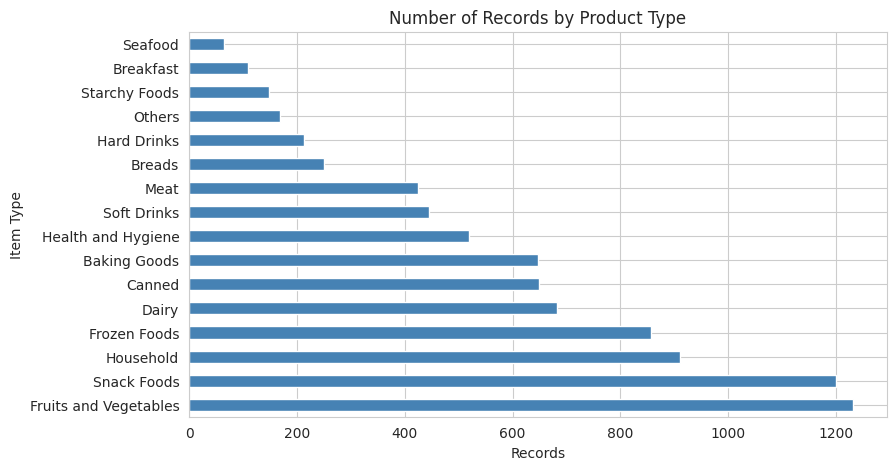

In [5]:
plt.figure(figsize=(9, 5))
df['Item Type'].value_counts().plot(kind='barh', color='steelblue')
plt.title('Number of Records by Product Type')
plt.xlabel('Records')
plt.show()

**What we see:** BlinkIT sells 1,559 different products in 16 types. The biggest ranges are **Fruits and Vegetables** (1,232 records) and **Snack Foods** (1,200). The smallest are Seafood (64) and Breakfast (110).

### Task 1.2: Types and locations of outlets

In [6]:
print(df['Outlet Type'].value_counts())
print()
print(df['Outlet Location Type'].value_counts())
print()
print(df['Outlet Size'].value_counts())

Outlet Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64

Outlet Location Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64

Outlet Size
Medium    3631
Small     3139
High      1753
Name: count, dtype: int64


In [7]:
outlets = df.groupby('Outlet Identifier')[['Outlet Type', 'Outlet Location Type', 'Outlet Establishment Year']].first()
outlets

,Outlet Type,Outlet Location Type,Outlet Establishment Year
Outlet Identifier,,,
OUT010,Grocery Store,Tier 3,2011
OUT013,Supermarket Type1,Tier 3,2014
OUT017,Supermarket Type1,Tier 2,2020
OUT018,Supermarket Type2,Tier 3,2022
OUT019,Grocery Store,Tier 1,2018
OUT027,Supermarket Type3,Tier 3,2018
OUT035,Supermarket Type1,Tier 2,2017
OUT045,Supermarket Type1,Tier 2,2015
OUT046,Supermarket Type1,Tier 1,2016


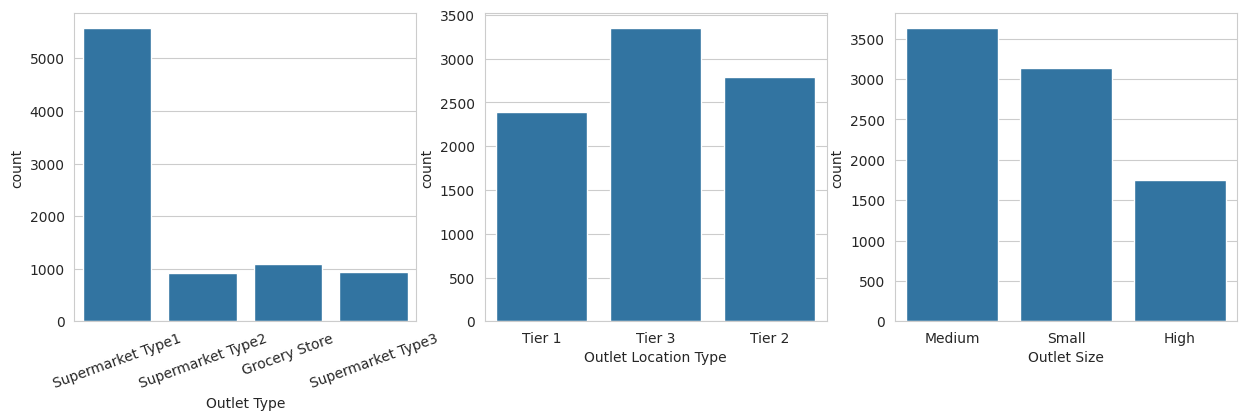

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x='Outlet Type', ax=axes[0])
sns.countplot(data=df, x='Outlet Location Type', ax=axes[1])
sns.countplot(data=df, x='Outlet Size', ax=axes[2])
axes[0].tick_params(axis='x', rotation=20)
plt.show()

**What we see:** There are 10 outlets. 6 are Supermarket Type1, 1 is Type2, 1 is Type3 and 2 are Grocery Stores. They are spread over Tier 1, Tier 2 and Tier 3 locations and were opened between 2011 and 2022.

### Task 1.3: How much is BlinkIT selling overall?

In [9]:
print('Total sales      :', round(df['Sales'].sum(), 2))
print('Average sales    :', round(df['Sales'].mean(), 2))
print('Median sales     :', round(df['Sales'].median(), 2))
print('Lowest sale      :', df['Sales'].min())
print('Highest sale     :', df['Sales'].max())

Total sales      : 1201681.49
Average sales    : 140.99
Median sales     : 143.01
Lowest sale      : 31.29
Highest sale     : 266.8884


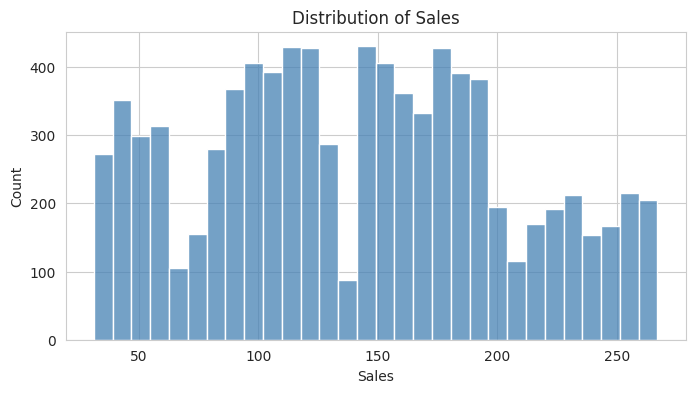

In [10]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Sales'], bins=30, color='steelblue')
plt.title('Distribution of Sales')
plt.show()

**What we see:** Total sales are about **1.2 million**. The average sale per record is about **141**, and sales range from about 31 to 267.

### Task 1.4: Customer ratings and product performance

In [11]:
print('Average rating:', round(df['Rating'].mean(), 2))
df.groupby('Item Type')['Rating'].mean().sort_values(ascending=False).round(2)

Average rating: 3.97


Item Type
Meat                     4.02
Household                4.00
Canned                   3.99
Health and Hygiene       3.99
Baking Goods             3.98
Frozen Foods             3.97
Dairy                    3.97
Seafood                  3.96
Fruits and Vegetables    3.96
Others                   3.95
Snack Foods              3.95
Breakfast                3.93
Soft Drinks              3.92
Starchy Foods            3.92
Hard Drinks              3.91
Breads                   3.88
Name: Rating, dtype: float64

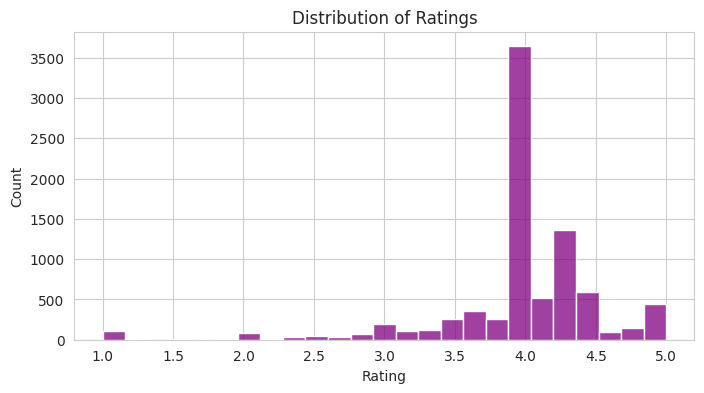

In [12]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Rating'], bins=25, color='purple')
plt.title('Distribution of Ratings')
plt.show()

**What we see:** The average rating is **3.97 out of 5**. All product types are close to each other (about 3.9 to 4.0). Meat is highest and Breads lowest. There are many ratings of exactly 5.0 and a smaller number of exactly 1.0, which we will check in Objective 2.

---
# Objective 2: Make Sure the Available Information Is Reliable

### Task 2.1: Missing information

In [13]:
df.isnull().sum()

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

In [14]:
# Which outlets have missing Item Weight?
df[df['Item Weight'].isnull()]['Outlet Identifier'].value_counts()

Outlet Identifier
OUT027    935
OUT019    528
Name: count, dtype: int64

In [15]:
# Visibility of exactly 0 does not make sense for a product that was sold
print('Rows with zero visibility:', (df['Item Visibility'] == 0).sum())

Rows with zero visibility: 526


**What we see:** Only `Item Weight` has missing values (1,463 rows). All of them come from outlets **OUT019 and OUT027**. Also, 526 rows have an `Item Visibility` of 0, which is not realistic, so we treat those as missing too.

**How we fix it:**
- Item Weight: the same product has the same weight in every outlet, so we copy the weight from another row of the same product.
- Item Visibility = 0: replace with the average visibility.

In [16]:
# Fix Item Weight: build a list of known weights for each product
known_weights = df.dropna(subset=['Item Weight']).drop_duplicates('Item Identifier')
known_weights = known_weights.set_index('Item Identifier')['Item Weight']

df['Item Weight'] = df['Item Weight'].fillna(df['Item Identifier'].map(known_weights))

# A few products have no weight anywhere, so use the overall median
df['Item Weight'] = df['Item Weight'].fillna(df['Item Weight'].median())

In [17]:
# Fix Item Visibility: replace 0 with the average of the non-zero values
avg_visibility = df[df['Item Visibility'] > 0]['Item Visibility'].mean()
df['Item Visibility'] = df['Item Visibility'].replace(0, avg_visibility)

print('Missing values left:', df.isnull().sum().sum())
print('Zero visibility left:', (df['Item Visibility'] == 0).sum())

Missing values left: 0
Zero visibility left: 0


### Task 2.2: Duplicate information

In [18]:
print('Duplicate rows:', df.duplicated().sum())
print('Same product repeated in the same outlet:', df.duplicated(['Item Identifier', 'Outlet Identifier']).sum())

Duplicate rows: 0
Same product repeated in the same outlet: 0


**What we see:** There are **no duplicates**. A product appearing in many outlets is normal, not a duplicate.

### Task 2.3: Unusually high or low values

In [19]:
df[['Sales', 'Item Visibility', 'Item Weight', 'Rating']].describe()

,Sales,Item Visibility,Item Weight,Rating
count,8523.000000,8523.000000,8523.000000,8523.000000
mean,140.992783,0.070482,12.875314,3.965857
std,62.275067,0.048730,4.645010,0.605651
min,31.290000,0.003575,4.555000,1.000000
25%,93.826500,0.033085,8.785000,4.000000
50%,143.012800,0.062517,12.650000,4.000000
75%,185.643700,0.094585,16.850000,4.200000
max,266.888400,0.328391,21.350000,5.000000


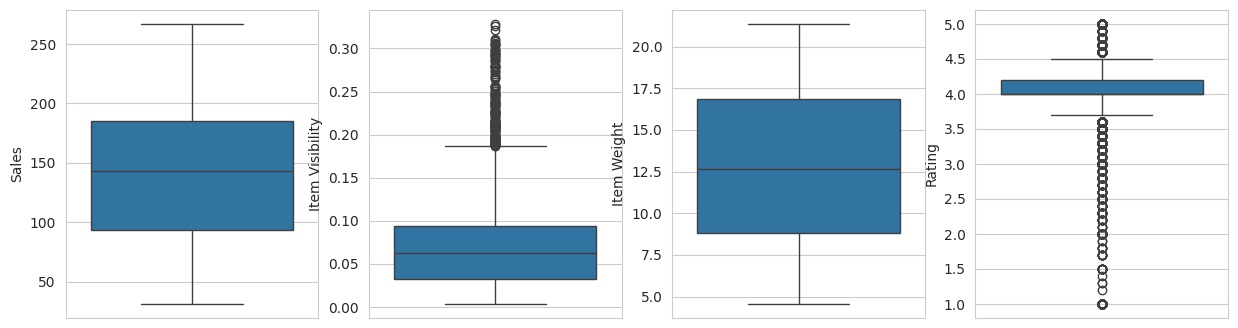

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
sns.boxplot(y=df['Sales'], ax=axes[0])
sns.boxplot(y=df['Item Visibility'], ax=axes[1])
sns.boxplot(y=df['Item Weight'], ax=axes[2])
sns.boxplot(y=df['Rating'], ax=axes[3])
plt.show()

**What we see:**
- `Sales` and `Item Weight` have no unusual values.
- `Item Visibility` has some high values (up to 0.33). These can be real (an item placed at the front of the store), so we keep them.
- `Rating` has some low values. These are real customer opinions, so we keep them. The many ratings of exactly 5.0 and exactly 1.0 should be checked at the source.

### Task 2.4: Make similar information consistent

In [21]:
# Fat content is written in 5 different ways
df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

In [22]:
df['Item Fat Content'] = df['Item Fat Content'].replace({'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'})

# Household, Health and Hygiene and Others are not food, so they cannot be 'Low Fat'
non_food = ['Household', 'Health and Hygiene', 'Others']
df.loc[df['Item Type'].isin(non_food), 'Item Fat Content'] = 'Non-Edible'

df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat       3918
Regular       3006
Non-Edible    1599
Name: count, dtype: int64

In [23]:
# Three outlets have more than one Outlet Size, but an outlet can only have one size
df.groupby('Outlet Identifier')['Outlet Size'].nunique()

Outlet Identifier
OUT010    3
OUT013    1
OUT017    3
OUT018    1
OUT019    1
OUT027    1
OUT035    1
OUT045    3
OUT046    1
OUT049    1
Name: Outlet Size, dtype: int64

In [24]:
# Use the size that appears most often for each of these outlets
df.loc[df['Outlet Identifier'] == 'OUT010', 'Outlet Size'] = 'Medium'
df.loc[df['Outlet Identifier'] == 'OUT017', 'Outlet Size'] = 'Small'
df.loc[df['Outlet Identifier'] == 'OUT045', 'Outlet Size'] = 'Medium'

df.groupby('Outlet Identifier')['Outlet Size'].nunique()

Outlet Identifier
OUT010    1
OUT013    1
OUT017    1
OUT018    1
OUT019    1
OUT027    1
OUT035    1
OUT045    1
OUT046    1
OUT049    1
Name: Outlet Size, dtype: int64

**Summary of cleaning**

| Problem | Fix |
|---|---|
| Fat content written 5 ways (`Low Fat`, `LF`, `low fat`, `Regular`, `reg`) | Changed to `Low Fat` and `Regular` |
| Non-food products labelled as Low Fat | Changed to `Non-Edible` |
| 3 outlets with more than one size | Used the most common size for each |
| Missing Item Weight (1,463 rows) | Filled from the same product in other outlets |
| Visibility of 0 (526 rows) | Replaced with the average |

**Note:** the three outlet sizes were split almost evenly in the raw data, so our choice is a best guess. Results by outlet size should be treated carefully until the real sizes are confirmed.

---
# Objective 3: What Is Driving Better Sales Performance?
We look at two numbers for each group:
- **Total sales:** how much the group sells in total (depends on how many rows it has)
- **Average sales:** how much a typical row sells (a fair way to compare groups of different sizes)

### Task 3.1: Which types of products are selling more?

In [25]:
product_sales = df.groupby('Item Type').agg(
    Records=('Sales', 'count'),
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'))
product_sales = product_sales.sort_values('Total_Sales', ascending=False).round(2)
product_sales

,Records,Total_Sales,Average_Sales
Item Type,,,
Fruits and Vegetables,1232,178124.08,144.58
Snack Foods,1200,175433.92,146.19
Household,910,135976.53,149.42
Frozen Foods,856,118558.88,138.50
Dairy,682,101276.46,148.50
Canned,649,90706.73,139.76
Baking Goods,648,81894.74,126.38
Health and Hygiene,520,68025.84,130.82
Meat,425,59449.86,139.88


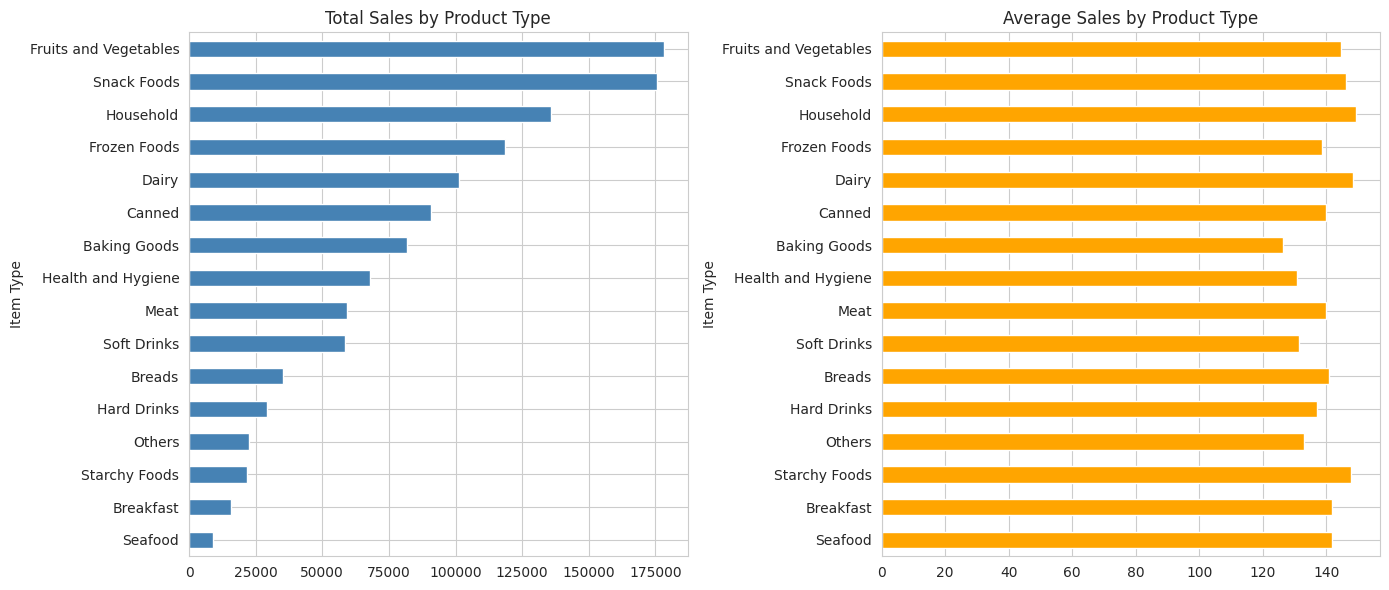

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
product_sales['Total_Sales'].plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Total Sales by Product Type')
axes[0].invert_yaxis()

product_sales['Average_Sales'].plot(kind='barh', ax=axes[1], color='orange')
axes[1].set_title('Average Sales by Product Type')
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

In [27]:
df.groupby('Item Fat Content')['Sales'].agg(['count', 'sum', 'mean']).round(2)

,count,sum,mean
Item Fat Content,,,
Low Fat,3918,549865.43,140.34
Non-Edible,1599,226454.26,141.62
Regular,3006,425361.80,141.50


**What we see:**
- **Fruits and Vegetables** (178k) and **Snack Foods** (175k) have the highest total sales, followed by Household, Frozen Foods and Dairy. These top five make up about **59%** of all sales.
- Average sales are fairly close across product types (about 126 to 149). Household, Dairy and Starchy Foods are slightly higher, and Baking Goods is the lowest. So the total-sales ranking mostly reflects **how many products each type has**.
- Fat content makes almost no difference (about 140 to 142).

### Task 3.2: Which types of outlets are performing better?

In [28]:
outlet_type_sales = df.groupby('Outlet Type').agg(
    Records=('Sales', 'count'),
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean')).round(2)
outlet_type_sales

,Records,Total_Sales,Average_Sales
Outlet Type,,,
Grocery Store,1083,151939.15,140.29
Supermarket Type1,5577,787549.89,141.21
Supermarket Type2,928,131477.78,141.68
Supermarket Type3,935,130714.67,139.80


In [29]:
location_sales = df.groupby('Outlet Location Type').agg(
    Records=('Sales', 'count'),
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean')).round(2)
location_sales

,Records,Total_Sales,Average_Sales
Outlet Location Type,,,
Tier 1,2388,336397.81,140.87
Tier 2,2785,393150.65,141.17
Tier 3,3350,472133.03,140.94


In [30]:
size_sales = df.groupby('Outlet Size').agg(
    Records=('Sales', 'count'),
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean')).round(2)
size_sales

,Records,Total_Sales,Average_Sales
Outlet Size,,,
High,932,131809.02,141.43
Medium,4277,601743.66,140.69
Small,3314,468128.82,141.26


In [31]:
outlet_sales = df.groupby('Outlet Identifier').agg(
    Records=('Sales', 'count'),
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean')).sort_values('Total_Sales', ascending=False).round(2)
outlet_sales

,Records,Total_Sales,Average_Sales
Outlet Identifier,,,
OUT035,930,133103.91,143.12
OUT046,930,132113.37,142.06
OUT013,932,131809.02,141.43
OUT018,928,131477.78,141.68
OUT045,929,130942.78,140.95
OUT027,935,130714.67,139.80
OUT049,930,130476.86,140.30
OUT017,926,129103.96,139.42
OUT010,555,78131.57,140.78


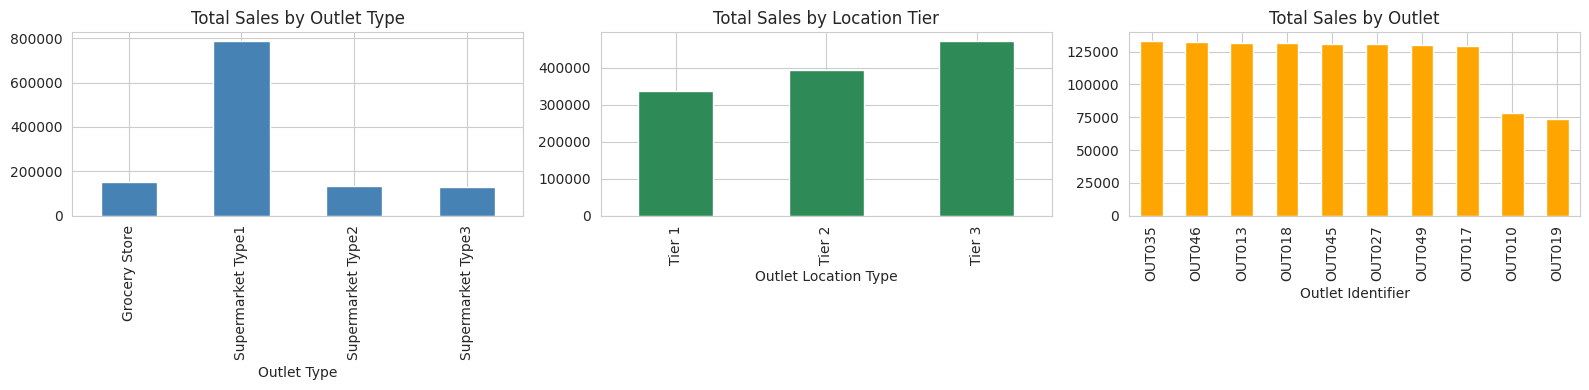

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
outlet_type_sales['Total_Sales'].plot(kind='bar', ax=axes[0], color='steelblue', title='Total Sales by Outlet Type')
location_sales['Total_Sales'].plot(kind='bar', ax=axes[1], color='seagreen', title='Total Sales by Location Tier')
outlet_sales['Total_Sales'].plot(kind='bar', ax=axes[2], color='orange', title='Total Sales by Outlet')
plt.tight_layout()
plt.show()

**What we see:**
- **Supermarket Type1** has the highest total sales (66%), but only because it has 6 of the 10 outlets. A single Type1 outlet sells about the same as the Type2 or Type3 outlet (about 130k to 133k).
- The two **Grocery Stores (OUT010 and OUT019)** have much lower total sales (about 74k to 78k each). They have about 40% fewer rows (about 540 vs 930), but the average sale per row is the same (about 140).
- **Tier 3** has the highest total, again because it has the most outlets (4). Average sales are the same in all tiers (about 141).
- Outlet size makes almost no difference to average sales.

### Task 3.3: Are visibility, weight, ratings and outlet characteristics connected with sales?

In [33]:
df[['Item Visibility', 'Item Weight', 'Rating', 'Outlet Establishment Year', 'Sales']].corr().round(3)

,Item Visibility,Item Weight,Rating,Outlet Establishment Year,Sales
Item Visibility,1.000,-0.018,-0.002,-0.057,-0.006
Item Weight,-0.018,1.000,0.004,-0.002,0.026
Rating,-0.002,0.004,1.000,0.000,0.011
Outlet Establishment Year,-0.057,-0.002,0.000,1.000,-0.001
Sales,-0.006,0.026,0.011,-0.001,1.000


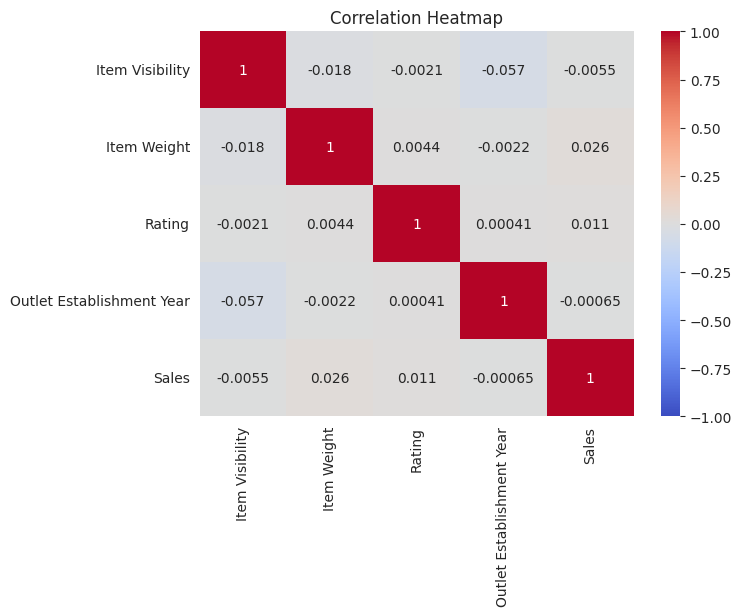

In [34]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[['Item Visibility', 'Item Weight', 'Rating', 'Outlet Establishment Year', 'Sales']].corr(),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

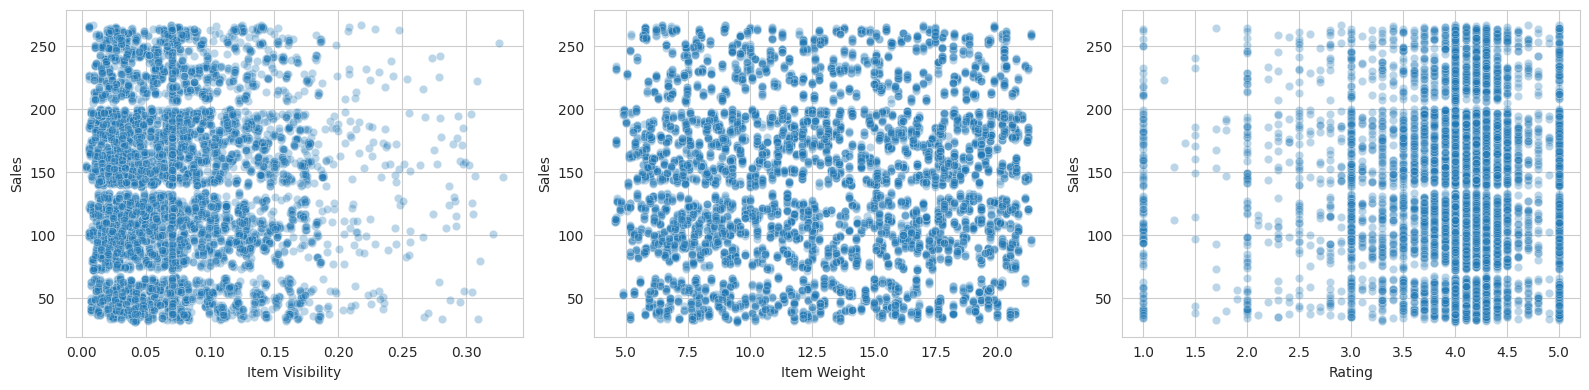

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x='Item Visibility', y='Sales', alpha=0.3, ax=axes[0])
sns.scatterplot(data=df, x='Item Weight', y='Sales', alpha=0.3, ax=axes[1])
sns.scatterplot(data=df, x='Rating', y='Sales', alpha=0.3, ax=axes[2])
plt.tight_layout()
plt.show()

In [36]:
df.groupby('Outlet Establishment Year')['Sales'].mean().round(2)

Outlet Establishment Year
2011    140.78
2012    140.30
2014    141.43
2015    140.95
2016    142.06
2017    143.12
2018    139.80
2020    139.42
2022    141.68
Name: Sales, dtype: float64

**What we see:** A correlation close to 0 means there is no link. All of the correlations with `Sales` are very close to 0:
- Item visibility: about 0
- Item weight: about 0.03 (almost none)
- Rating: about 0.01

The scatter plots look like a random cloud, and the average sales for each outlet year are about the same. So in this data, **higher visibility, heavier products, better ratings, bigger outlets or newer outlets do not lead to higher sales per row.**

### Task 3.4: Compare better and lower performing products and outlets

In [37]:
# Compare the top 25% of sales rows with the bottom 25%
top = df[df['Sales'] >= df['Sales'].quantile(0.75)]
bottom = df[df['Sales'] <= df['Sales'].quantile(0.25)]

comparison = pd.DataFrame({
    'Top 25% of sales': top[['Sales', 'Item Visibility', 'Item Weight', 'Rating']].mean(),
    'Bottom 25% of sales': bottom[['Sales', 'Item Visibility', 'Item Weight', 'Rating']].mean()}).round(3)
comparison

,Top 25% of sales,Bottom 25% of sales
Sales,222.805,61.938
Item Visibility,0.070,0.071
Item Weight,13.067,12.805
Rating,3.965,3.965


In [38]:
# Outlet type mix in both groups (percent)
pd.DataFrame({
    'Top 25%': top['Outlet Type'].value_counts(normalize=True) * 100,
    'Bottom 25%': bottom['Outlet Type'].value_counts(normalize=True) * 100}).round(1)

,Top 25%,Bottom 25%
Outlet Type,,
Grocery Store,12.3,12.9
Supermarket Type1,65.7,65.0
Supermarket Type2,11.4,10.7
Supermarket Type3,10.6,11.3


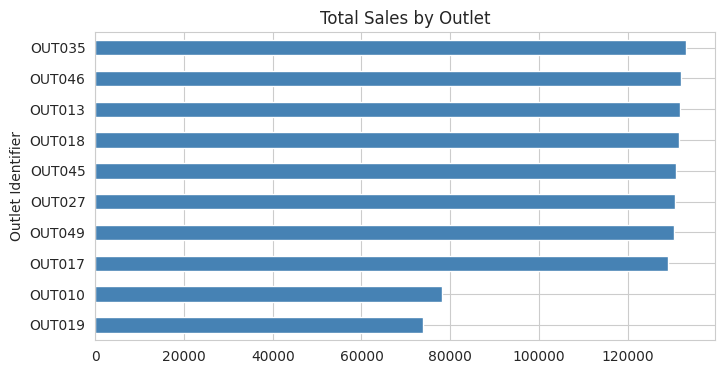

In [39]:
# Best and worst outlets by total sales
outlet_sales['Total_Sales'].sort_values().plot(kind='barh', color='steelblue', figsize=(8, 4))
plt.title('Total Sales by Outlet')
plt.show()

**What we see:**
- **Products:** high-selling and low-selling rows look almost the same in visibility, weight, rating and outlet type. So these details do not explain why some rows sell more.
- **Outlets:** eight outlets each sell about 129k to 133k. The two Grocery Stores sell about 74k to 78k. The difference comes from **how many products are sold**, not from how much each product sells.

---
# Objective 4: Help Management Make Better Business Decisions

### Task 4.1: Products contributing more to sales

In [40]:
product_total = df.groupby(['Item Identifier', 'Item Type']).agg(
    Total_Sales=('Sales', 'sum'),
    Outlets_Selling=('Outlet Identifier', 'nunique')).reset_index()

product_total.sort_values('Total_Sales', ascending=False).head(10).round(2)

,Item Identifier,Item Type,Total_Sales,Outlets_Selling
976,FDU12,Baking Goods,2371.01,9
921,FDT07,Fruits and Vegetables,2306.90,9
1454,NCQ06,Household,2294.71,9
616,FDL58,Snack Foods,2111.65,8
1279,NCB31,Household,2104.73,8
1141,FDX31,Fruits and Vegetables,2104.46,9
359,FDF05,Frozen Foods,2103.13,8
866,FDR59,Breads,2096.58,8
753,FDP28,Frozen Foods,2087.85,8
148,FDA04,Frozen Foods,2072.07,8


In [41]:
# Do products sold in more outlets have higher total sales?
print('Correlation:', round(product_total['Outlets_Selling'].corr(product_total['Total_Sales']), 2))
product_total.groupby('Outlets_Selling')['Total_Sales'].mean().round(0)

Correlation: 0.53


Outlets_Selling
1      137.0
2      313.0
3      413.0
4      564.0
5      708.0
6      846.0
7      953.0
8     1141.0
9     1521.0
10    1118.0
Name: Total_Sales, dtype: float64

**What we see:** The top 10 products are each sold in **8 or 9 of the 10 outlets**. Products sold in more outlets have higher total sales (correlation about 0.53). So **wider distribution is a clear way to grow sales.**

### Task 4.2: Outlets and locations performing better

In [42]:
outlet_details = df.groupby(['Outlet Identifier', 'Outlet Type', 'Outlet Location Type']).agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean')).sort_values('Total_Sales', ascending=False).round(2)
outlet_details

,,,Total_Sales,Average_Sales
Outlet Identifier,Outlet Type,Outlet Location Type,,
OUT035,Supermarket Type1,Tier 2,133103.91,143.12
OUT046,Supermarket Type1,Tier 1,132113.37,142.06
OUT013,Supermarket Type1,Tier 3,131809.02,141.43
OUT018,Supermarket Type2,Tier 3,131477.78,141.68
OUT045,Supermarket Type1,Tier 2,130942.78,140.95
OUT027,Supermarket Type3,Tier 3,130714.67,139.80
OUT049,Supermarket Type1,Tier 1,130476.86,140.30
OUT017,Supermarket Type1,Tier 2,129103.96,139.42
OUT010,Grocery Store,Tier 3,78131.57,140.78


In [43]:
df.pivot_table(index='Outlet Type', columns='Outlet Location Type', values='Sales', aggfunc='sum').round(0)

Outlet Location Type,Tier 1,Tier 2,Tier 3
Outlet Type,,,
Grocery Store,73808.0,NaN,78132.0
Supermarket Type1,262590.0,393151.0,131809.0
Supermarket Type2,NaN,NaN,131478.0
Supermarket Type3,NaN,NaN,130715.0


**What we see:** The best outlet is **OUT035** (133k), but the top 8 outlets are all very close (129k to 133k). The lowest are the Grocery Stores **OUT010** and **OUT019**.

### Task 4.3: Where can performance be improved?

In [44]:
# Product types with average sales below the overall average
overall_avg = df['Sales'].mean()
product_sales[product_sales['Average_Sales'] < overall_avg].sort_values('Average_Sales')

,Records,Total_Sales,Average_Sales
Item Type,,,
Baking Goods,648,81894.74,126.38
Health and Hygiene,520,68025.84,130.82
Soft Drinks,445,58514.17,131.49
Others,169,22451.89,132.85
Hard Drinks,214,29334.68,137.08
Frozen Foods,856,118558.88,138.50
Canned,649,90706.73,139.76
Meat,425,59449.86,139.88
Breads,251,35379.12,140.95


In [45]:
# Number of different products each outlet type sells
df.groupby('Outlet Type')['Item Identifier'].nunique()

Outlet Type
Grocery Store         901
Supermarket Type1    1550
Supermarket Type2     928
Supermarket Type3     935
Name: Item Identifier, dtype: int64

**What we see:**
- **Weakest product types:** Baking Goods (about 126), Health and Hygiene, Soft Drinks and Others sell below the company average (141) per row.
- **Weakest outlets:** the two Grocery Stores sell about 40% less in total, and they sell fewer products than the supermarkets.
- **Data quality:** outlet size, item weight, visibility and ratings had problems that limit what we can conclude.

### Task 4.4: Practical suggestions

1. **Add more products to the two Grocery Stores (OUT010 and OUT019).** They sell the same amount per product as other outlets, but sell fewer products. Matching the supermarkets could add roughly 50k of sales to each.
2. **Sell proven products in more outlets.** Products sold in more outlets have higher total sales, so listing the best products in the outlets that do not carry them is a low-risk way to grow.
3. **Keep the top five product types well stocked:** Fruits and Vegetables, Snack Foods, Household, Frozen Foods and Dairy (about 59% of sales).
4. **Review Baking Goods, Health and Hygiene and Soft Drinks.** They sell below average per product. Try different prices, pack sizes or offers.
5. **Do not spend money on shelf visibility, product weight or bigger outlets based only on this data.** None of them is linked to sales here. Test on a small scale first.
6. **Collect more data** such as price, promotions, number of customers and sale dates. The current columns explain very little about why sales differ.
7. **Fix data problems at the source:** fat content spellings, one size per outlet, missing weights for OUT019 and OUT027, zero visibility values and unusual ratings.

---
## Conclusion
BlinkIT's sales depend mainly on **how many products are sold**, not on product weight, visibility, rating or outlet size. The average sale is about 141 almost everywhere. The best opportunities are to **add products to the two Grocery Stores** and to **sell the best products in more outlets**.